In [61]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/citrnminhtin/diabetes-prediction-dataset/diabetes_prediction_dataset.csv


In [62]:

from pathlib import Path

# Kiem tra cac file CSV da them vao Kaggle
csv_files = list(Path("/kaggle/input").rglob("*.csv"))

print("So file CSV:", len(csv_files))

for file in csv_files:
    print(file)


So file CSV: 1
/kaggle/input/datasets/citrnminhtin/diabetes-prediction-dataset/diabetes_prediction_dataset.csv


In [63]:

import pandas as pd

# Lay duong dan file CSV da tim duoc
data_path = csv_files[0]

# Doc du lieu
df = pd.read_csv(data_path)

# Hien thi kich thuoc
print("Kich thuoc du lieu:", df.shape)

# Hien thi ten cac cot
print("\nDanh sach cac cot:")
print(df.columns.tolist())

# Hien thi 5 dong dau
print("\n5 dong du lieu dau tien:")
display(df.head())


Kich thuoc du lieu: (100000, 9)

Danh sach cac cot:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

5 dong du lieu dau tien:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [64]:

# Kiem tra kieu du lieu
print("THONG TIN DATASET:")
df.info()

# Kiem tra gia tri thieu
print("\nSO GIA TRI THIEU:")
print(df.isnull().sum())

# Kiem tra du lieu trung lap
print("\nSO DONG TRUNG LAP:")
print(df.duplicated().sum())

# Thong ke mo ta du lieu
print("\nTHONG KE DU LIEU:")
display(df.describe(include="all"))


THONG TIN DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

SO GIA TRI THIEU:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000,100000.000000,100000.00000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN
freq,58552,NaN,NaN,NaN,35816,NaN,NaN,NaN,NaN
mean,NaN,41.885856,0.07485,0.039420,NaN,27.320767,5.527507,138.058060,0.085000
std,NaN,22.516840,0.26315,0.194593,NaN,6.636783,1.070672,40.708136,0.278883
min,NaN,0.080000,0.00000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000
25%,NaN,24.000000,0.00000,0.000000,NaN,23.630000,4.800000,100.000000,0.000000
50%,NaN,43.000000,0.00000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000
75%,NaN,60.000000,0.00000,0.000000,NaN,29.580000,6.200000,159.000000,0.000000


In [65]:

# Kiem tra so luong tung nhan
print("PHAN BO NHAN DIABETES:")
print(df['diabetes'].value_counts())

# Tinh ty le phan tram
print("\nTY LE PHAN TRAM:")
print(df['diabetes'].value_counts(normalize=True) * 100)


PHAN BO NHAN DIABETES:
diabetes
0    91500
1     8500
Name: count, dtype: int64

TY LE PHAN TRAM:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


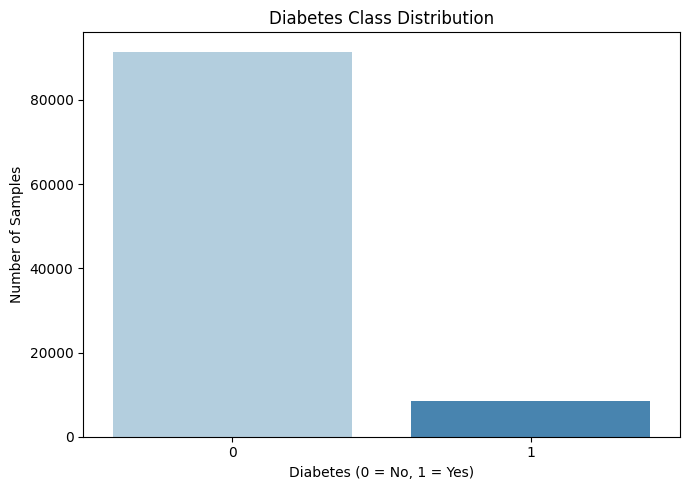

In [66]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='diabetes',
    hue='diabetes',
    palette='Blues',
    legend=False
)

plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Number of Samples")

plt.tight_layout()

# Luu bieu do
plt.savefig(
    "/kaggle/working/diabetes_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [67]:

# Kiem tra gia tri thieu
print("GIA TRI THIEU:")
print(df.isnull().sum())

# Kiem tra du lieu trung lap
duplicate_count = df.duplicated().sum()

print("\nSO DONG TRUNG LAP:")
print(duplicate_count)

# Kiem tra kieu du lieu
print("\nKIEU DU LIEU:")
print(df.dtypes)


GIA TRI THIEU:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

SO DONG TRUNG LAP:
3854

KIEU DU LIEU:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


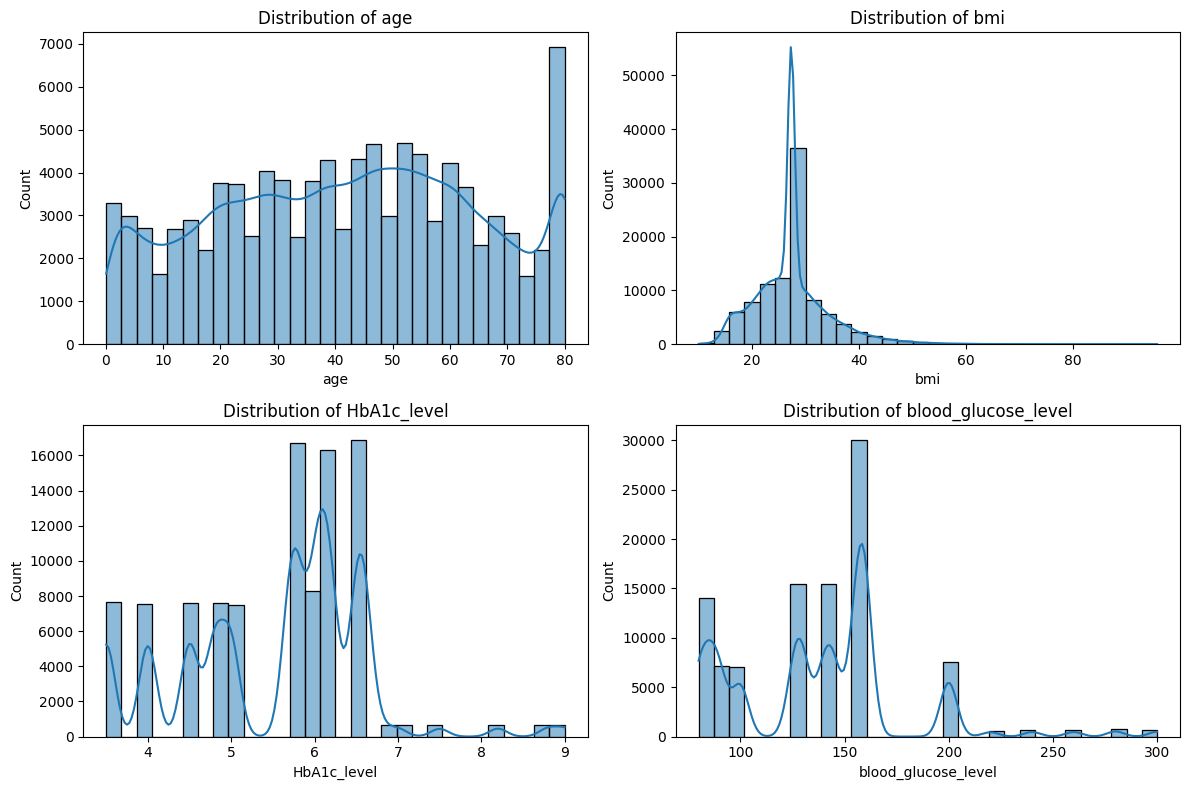

In [68]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/diabetes_feature_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [69]:

# Lay cac cot dang chuoi
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

print("CAC COT DU LIEU PHAN LOAI:")

for col in categorical_cols:
    print(f"\nCot: {col}")
    print(df[col].value_counts(dropna=False))


CAC COT DU LIEU PHAN LOAI:

Cot: gender
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Cot: smoking_history
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [70]:

# Tao ban sao va xu ly du lieu
df_clean = df.copy()

# Loai bo dong thieu nhan
df_clean = df_clean.dropna(subset=['diabetes'])

# Loai bo cac dong trung lap hoan toan
df_clean = df_clean.drop_duplicates()

# Tach dac trung va nhan
X = df_clean.drop(columns=['diabetes'])
y = df_clean['diabetes']

print("Kich thuoc X:", X.shape)
print("Kich thuoc y:", y.shape)
print("Phan bo nhan:")
print(y.value_counts())


Kich thuoc X: (96146, 8)
Kich thuoc y: (96146,)
Phan bo nhan:
diabetes
0    87664
1     8482
Name: count, dtype: int64


In [71]:

from sklearn.model_selection import train_test_split

# Chia du lieu 80% train - 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (76916, 8)
X_test: (19230, 8)
y_train: (76916,)
y_test: (19230,)


In [72]:

# Xac dinh cac cot so
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

# Xac dinh cac cot dang chu
categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print("Cac cot so:")
print(numeric_features)

print("\nCac cot phan loai:")
print(categorical_features)


Cac cot so:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Cac cot phan loai:
['gender', 'smoking_history']


In [73]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Xu ly cac cot so
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Xu ly cac cot phan loai
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Ket hop hai cach xu ly
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Da khoi tao bo tien xu ly thanh cong!")


Da khoi tao bo tien xu ly thanh cong!


In [74]:

from sklearn.model_selection import train_test_split

# Lay 10000 mau tu tap Train
X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    random_state=42,
    stratify=y_train
)

print("Train ban dau:", X_train.shape)
print("Train su dung:", X_train_small.shape)
print("Test:", X_test.shape)

print("\nPhan bo nhan Train:")
print(y_train_small.value_counts())


Train ban dau: (76916, 8)
Train su dung: (10000, 8)
Test: (19230, 8)

Phan bo nhan Train:
diabetes
0    9118
1     882
Name: count, dtype: int64


In [75]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
import time

# Tao mo hinh SVM ket hop tien xu ly
svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('svm', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale'
    ))
])

# Bat dau tinh thoi gian
start_time = time.time()

# Huan luyen mo hinh
svm_model.fit(X_train_small, y_train_small)

# Thoi gian huan luyen
training_time = time.time() - start_time

print("Huan luyen SVM thanh cong!")
print(f"Thoi gian huan luyen: {training_time:.2f} giay")


Huan luyen SVM thanh cong!
Thoi gian huan luyen: 0.72 giay


In [76]:

# Du doan tren tap Test
y_pred = svm_model.predict(X_test)

print("10 nhan thuc te:")
print(y_test.iloc[:10].to_numpy())

print("\n10 nhan du doan:")
print(y_pred[:10])


10 nhan thuc te:
[0 0 0 0 0 0 0 0 0 0]

10 nhan du doan:
[0 0 0 0 0 0 0 0 0 0]


In [77]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Tinh cac chi so danh gia
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("===== DIABETES SVM EVALUATION =====")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")


===== DIABETES SVM EVALUATION =====
Accuracy : 96.16%
Precision: 95.18%
Recall   : 59.43%
F1-score : 73.18%


In [78]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Tao Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

# Chuyen thanh DataFrame
conf_matrix = pd.DataFrame(
    cm,
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

print("CONFUSION MATRIX:")
display(conf_matrix)


CONFUSION MATRIX:


,Predicted 0,Predicted 1
Actual 0,17483,51
Actual 1,688,1008


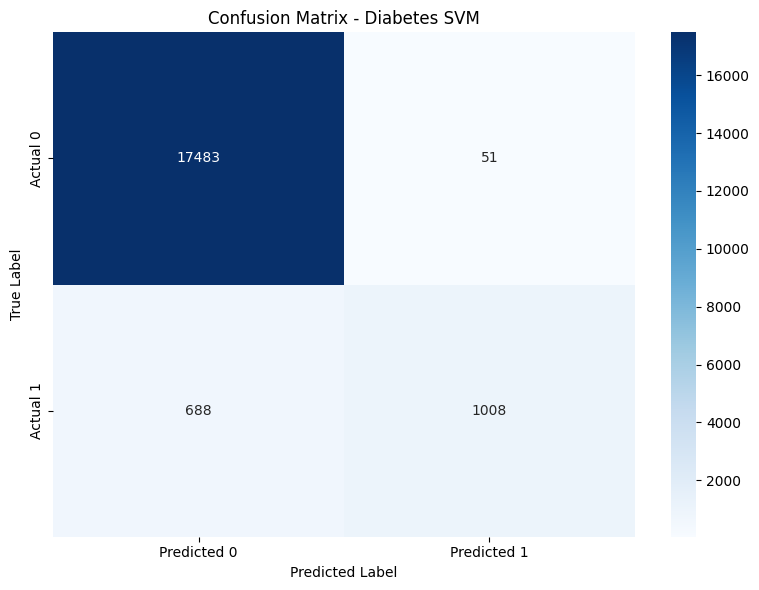

Da luu Confusion Matrix thanh cong!


In [79]:

import matplotlib.pyplot as plt
import seaborn as sns

# Tao bieu do Confusion Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Diabetes SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

# Luu bieu do PNG
plt.savefig(
    "/kaggle/working/diabetes_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Da luu Confusion Matrix thanh cong!")


In [80]:

# Lay cac gia tri tu Confusion Matrix
tn, fp, fn, tp = cm.ravel()

print("===== CONFUSION MATRIX ANALYSIS =====")

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

print("\nTong so mau Test:", len(y_test))

print("So mau du doan dung:", tn + tp)
print("So mau du doan sai:", fp + fn)


===== CONFUSION MATRIX ANALYSIS =====
True Negative : 17483
False Positive: 51
False Negative: 688
True Positive : 1008

Tong so mau Test: 19230
So mau du doan dung: 18491
So mau du doan sai: 739


In [81]:

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Tinh accuracy
accuracy = accuracy_score(y_test, y_pred)

# Tao bao cao chi tiet
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['No Diabetes', 'Diabetes'],
    digits=4,
    zero_division=0
)

print("===== DIABETES SVM REPORT =====")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(report)


===== DIABETES SVM REPORT =====
Accuracy: 96.16%

Classification Report:
              precision    recall  f1-score   support

 No Diabetes     0.9621    0.9971    0.9793     17534
    Diabetes     0.9518    0.5943    0.7318      1696

    accuracy                         0.9616     19230
   macro avg     0.9570    0.7957    0.8555     19230
weighted avg     0.9612    0.9616    0.9575     19230



In [82]:

from pathlib import Path

output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

# Luu bao cao TXT
with open(
    output_dir / "diabetes_evaluation.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("DIABETES SVM EVALUATION\n\n")
    f.write("Model: SVC(kernel='rbf', C=1.0)\n")
    f.write("Training subset: 10000 samples\n")
    f.write(f"Test samples: {len(y_test)}\n")
    f.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")
    f.write("Confusion Matrix:\n")
    f.write(str(conf_matrix))
    f.write("\n\nClassification Report:\n")
    f.write(report)

print("Da luu bao cao Diabetes thanh cong!")


Da luu bao cao Diabetes thanh cong!


In [83]:

from sklearn.model_selection import train_test_split

# Lay 3000 mau tu tap train de toi uu tham so
X_train_tune, _, y_train_tune, _ = train_test_split(
    X_train_small,
    y_train_small,
    train_size=3000,
    random_state=42,
    stratify=y_train_small
)

print("Du lieu toi uu:", X_train_tune.shape)
print("Phan bo nhan:")
print(y_train_tune.value_counts())


Du lieu toi uu: (3000, 8)
Phan bo nhan:
diabetes
0    2735
1     265
Name: count, dtype: int64


In [84]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# Tao pipeline moi, chuan hoa trong tung fold
pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('svm', SVC())
])

# Danh sach tham so
param_grid = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale']
    }
]

# Chia 3 fold
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Tim tham so tot nhat
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=2,
    refit=True,
    verbose=1
)

# Huan luyen
grid_search.fit(X_train_tune, y_train_tune)

print("\nBest Parameters:")
print(grid_search.best_params_)

print(f"Best CV F1-score: {grid_search.best_score_:.4f}")


Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best Parameters:
{'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV F1-score: 0.7775


In [85]:

import pandas as pd

# Lay ket qua GridSearchCV
cv_results = pd.DataFrame(grid_search.cv_results_)

# Lay cac cot quan trong
result_table = cv_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]]

# Sap xep theo thu hang
result_table = result_table.sort_values(
    by='rank_test_score'
)

display(result_table)


,params,mean_test_score,std_test_score,rank_test_score
5,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke...",0.777465,0.031870,1
4,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.772862,0.021477,2
1,"{'svm__C': 1, 'svm__kernel': 'linear'}",0.755788,0.029903,3
2,"{'svm__C': 10, 'svm__kernel': 'linear'}",0.755393,0.028185,4
0,"{'svm__C': 0.1, 'svm__kernel': 'linear'}",0.748305,0.034168,5
3,"{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__k...",0.514334,0.035877,6


In [86]:

from sklearn.base import clone

# Lay mo hinh co tham so tot nhat
best_model = clone(grid_search.best_estimator_)

# Huan luyen lai tren 10000 mau Train
best_model.fit(X_train_small, y_train_small)

# Du doan tren tap Test
y_pred_best = best_model.predict(X_test)

print("Da huan luyen lai mo hinh toi uu!")
print("Best Parameters:", grid_search.best_params_)


Da huan luyen lai mo hinh toi uu!
Best Parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}


In [87]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Ham danh gia mo hinh
def evaluate(y_true, y_predict):
    return {
        'Accuracy': accuracy_score(y_true, y_predict),
        'Precision': precision_score(
            y_true, y_predict, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_predict, zero_division=0
        ),
        'F1-score': f1_score(
            y_true, y_predict, zero_division=0
        )
    }

# So sanh hai mo hinh
comparison = pd.DataFrame({
    'SVM ban dau': evaluate(y_test, y_pred),
    'SVM toi uu': evaluate(y_test, y_pred_best)
}).T

display((comparison * 100).round(2))


,Accuracy,Precision,Recall,F1-score
SVM ban dau,96.16,95.18,59.43,73.18
SVM toi uu,96.13,92.73,60.91,73.52


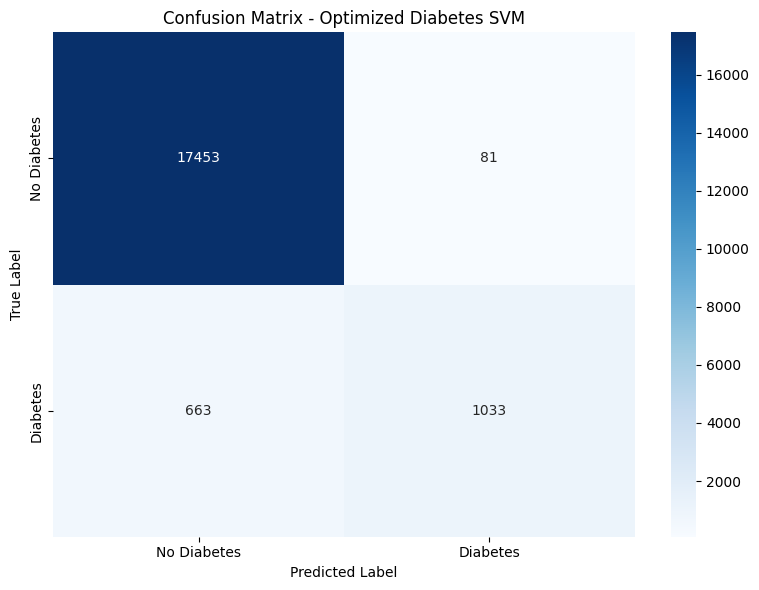

In [88]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_best = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_best,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title("Confusion Matrix - Optimized Diabetes SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/diabetes_optimized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [89]:

from pathlib import Path

# Tao thu muc ket qua
output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

# Chuyen ket qua sang phan tram
comparison_percent = (comparison * 100).round(2)

# Luu bang so sanh
comparison_percent.to_csv(
    output_dir / "diabetes_model_comparison.csv",
    encoding="utf-8-sig"
)

print("BANG SO SANH MO HINH:")
display(comparison_percent)

print("Da luu file CSV thanh cong!")


BANG SO SANH MO HINH:


,Accuracy,Precision,Recall,F1-score
SVM ban dau,96.16,95.18,59.43,73.18
SVM toi uu,96.13,92.73,60.91,73.52


Da luu file CSV thanh cong!


In [90]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Danh gia mo hinh toi uu
final_accuracy = accuracy_score(y_test, y_pred_best)

final_report = classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=["No Diabetes", "Diabetes"],
    digits=4,
    zero_division=0
)

final_cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

# Xuat bao cao
with open(
    "/kaggle/working/diabetes_final_report.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("DIABETES SVM FINAL REPORT\n\n")

    f.write("Best Parameters:\n")
    f.write(str(grid_search.best_params_))

    f.write("\n\nBest CV F1-score:\n")
    f.write(str(grid_search.best_score_))

    f.write("\n\nTraining samples:\n")
    f.write(str(len(y_train_small)))

    f.write("\n\nTesting samples:\n")
    f.write(str(len(y_test)))

    f.write("\n\nTest Accuracy:\n")
    f.write(f"{final_accuracy * 100:.2f}%")

    f.write("\n\nClassification Report:\n")
    f.write(final_report)

    f.write("\nConfusion Matrix:\n")
    f.write(str(final_cm))

print("Da luu bao cao danh gia thanh cong!")
print(final_report)


Da luu bao cao danh gia thanh cong!
              precision    recall  f1-score   support

 No Diabetes     0.9634    0.9954    0.9791     17534
    Diabetes     0.9273    0.6091    0.7352      1696

    accuracy                         0.9613     19230
   macro avg     0.9453    0.8022    0.8572     19230
weighted avg     0.9602    0.9613    0.9576     19230



### NHẬN XÉT KẾT QUẢ THỰC NGHIỆM SVM TRÊN DIABETES DATASET

**1. Mô tả bài toán**

Bài thực hành xây dựng mô hình Support Vector Machine (SVM) để phân loại tình trạng mắc bệnh tiểu đường dựa trên các đặc trưng sức khỏe gồm tuổi, giới tính, tình trạng tăng huyết áp, bệnh tim, tiền sử hút thuốc, BMI, HbA1c và mức đường huyết.

Tập dữ liệu có 100.000 mẫu, 8 đặc trưng đầu vào và một biến mục tiêu `diabetes`.

- Nhãn 0: Không mắc bệnh tiểu đường (91.500 mẫu, chiếm 91,5%).
- Nhãn 1: Mắc bệnh tiểu đường (8.500 mẫu, chiếm 8,5%).

Dữ liệu có sự mất cân bằng giữa hai lớp.

**2. Tiền xử lý dữ liệu**

Tập dữ liệu ban đầu gồm 100.000 mẫu và 9 cột, trong đó có 8 đặc trưng đầu vào và một biến mục tiêu `diabetes`.

Quá trình khám phá dữ liệu không phát hiện giá trị thiếu nhưng xác định được 3.854 bản ghi trùng lặp hoàn toàn. Các bản ghi này được loại bỏ trước khi phân chia dữ liệu nhằm hạn chế việc các bản ghi giống hệt nhau xuất hiện đồng thời trong tập huấn luyện và kiểm tra.

Sau khi xử lý, tập dữ liệu còn **96.146 mẫu**, bao gồm:

- Không mắc tiểu đường (0): 87.664 mẫu.
- Mắc tiểu đường (1): 8.482 mẫu.

Dữ liệu được chia theo tỷ lệ 80% huấn luyện và 20% kiểm tra, với `random_state=42` và `stratify=y`.

Các đặc trưng số được chuẩn hóa bằng StandardScaler. Các đặc trưng phân loại được mã hóa bằng OneHotEncoder. Quá trình tiền xử lý được thực hiện thông qua Pipeline.

Để giảm thời gian thực nghiệm, mô hình SVM được huấn luyện trên 10.000 mẫu lấy từ tập huấn luyện. GridSearchCV sử dụng 3.000 mẫu để lựa chọn bộ siêu tham số.

**3. Xây dựng và tối ưu mô hình**

Mô hình SVM ban đầu sử dụng SVC với kernel RBF, C = 1 và gamma = scale.

GridSearchCV được sử dụng để lựa chọn tham số tối ưu thông qua 3-fold Cross-Validation trên 3.000 mẫu huấn luyện. Các kernel được khảo sát gồm linear và RBF, với C nhận các giá trị 0.1, 1 và 10.

Kết quả tham số tốt nhất:

- Kernel: **RBF**.
- C: **10**.
- Gamma: **scale**.
- Best CV F1-score: **77,75%**.

Mô hình sau tối ưu được huấn luyện lại trên 10.000 mẫu và đánh giá trên 19.230 mẫu kiểm tra.

**4. Kết quả đánh giá**

| Chỉ số | SVM ban đầu | SVM tối ưu |
|---|---|---|
| Accuracy | 96,16% | 96,13% |
| Precision | 95,18% | 92,73% |
| Recall | 59,43% | 60,91% |
| F1-score | 73,18% | 73,52% |

Các chỉ số Precision, Recall và F1-score được tính đối với lớp mắc bệnh tiểu đường (nhãn 1).

Mô hình ban đầu có Confusion Matrix:

- True Negative (TN): 17.483.
- False Positive (FP): 51.
- False Negative (FN): 688.
- True Positive (TP): 1.008.

Mô hình sau GridSearchCV có Confusion Matrix:

- True Negative (TN): 17.453.
- False Positive (FP): 81.
- False Negative (FN): 663.
- True Positive (TP): 1.033.

**5. Phân tích kết quả**

Sau tối ưu, Recall tăng từ 59,43% lên 60,91%, tương đương mức tăng 1,48 điểm phần trăm. Mô hình phát hiện thêm 25 trường hợp mắc bệnh và giảm số lượng False Negative từ 688 xuống 663.

F1-score tăng từ 73,18% lên 73,52%, cho thấy sự cải thiện nhẹ về khả năng cân bằng Precision và Recall.

Tuy nhiên, Precision giảm từ 95,18% xuống 92,73% và số trường hợp False Positive tăng từ 51 lên 81.

Accuracy cũng giảm nhẹ từ 96,16% xuống 96,13%.

Như vậy, GridSearchCV giúp cải thiện F1-score và Recall trên tập kiểm tra, nhưng sự cải thiện này đi kèm với việc giảm nhẹ Precision và Accuracy.

**6. Kết luận**

Mô hình Support Vector Machine có khả năng phân loại dữ liệu bệnh tiểu đường với Accuracy trên 96% trong thực nghiệm.

Sau khi tối ưu bằng GridSearchCV, mô hình SVM với kernel RBF, C = 10 và gamma = scale đạt F1-score 73,52%, cao hơn mô hình ban đầu.

Tuy nhiên, Recall của lớp mắc bệnh chỉ đạt 60,91%, nghĩa là vẫn còn nhiều trường hợp mắc bệnh chưa được nhận diện đúng.

Kết quả cho thấy cần đánh giá đồng thời Accuracy, Precision, Recall và F1-score, đặc biệt khi dữ liệu có sự mất cân bằng giữa hai lớp.

Các hướng cải thiện tiếp theo gồm điều chỉnh class_weight, mở rộng tìm kiếm tham số và thử nghiệm trên nhiều tập dữ liệu khác nhau.

Kết quả thực nghiệm phục vụ mục đích nghiên cứu và học tập, không thay thế chẩn đoán y khoa.

In [91]:

import sys
import sklearn
import pandas as pd
import numpy as np

print("Python:", sys.version.split()[0])
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\nKIEM TRA KET QUA:")
print("Train:", X_train_small.shape)
print("Test:", X_test.shape)

assert len(y_pred_best) == len(y_test), \
    "So luong du doan khong khop!"

assert np.isfinite(final_accuracy), \
    "Accuracy khong hop le!"

print("Kiem tra ket qua thanh cong!")


Python: 3.13.15
Scikit-learn: 1.6.1
Pandas: 2.3.3
NumPy: 2.1.3

KIEM TRA KET QUA:
Train: (10000, 8)
Test: (19230, 8)
Kiem tra ket qua thanh cong!
